In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_parquet('../data/processed/features.parquet')
df['date'] = pd.to_datetime(df.cutoff, unit='s')

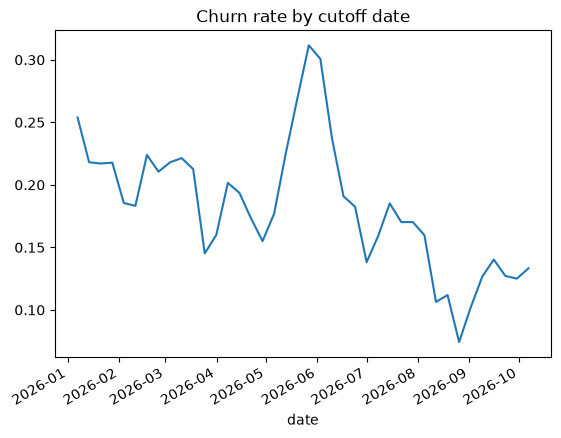

In [3]:
df.groupby('date').churn.mean().plot(title='Churn rate by cutoff date')
plt.show()

In [4]:
print(df.groupby('churn')[['matches_30d', 'days_since_last', 'win_rate_30d', 'activity_trend']].mean())

       matches_30d  days_since_last  win_rate_30d  activity_trend
churn                                                            
0        37.659282         4.749038      0.487978        0.455047
1         9.313883        13.274268      0.415002        0.277538


### Key EDA Observations

* **Churners play drastically less and show a steep drop in active engagement:** Users who churned (`churn = 1`) only averaged around 9 matches over the last 30 days compared to retained users who averaged over 37 matches. This is heavily backed by their `activity_trend` score, which is much lower for churners (0.28 vs 0.46).
* **Prolonged absence is a major indicator of a user leaving:** On average, churned users had not played a match in over 13 days (`days_since_last`), whereas retained users typically returned to play within less than 5 days.
* **Churn spiked dramatically mid-year but has since hit an all-time low:** The churn rate experienced a massive spike in late May / early June 2026, reaching over 30%. However, it steadily declined afterward, hitting a record low of under 10% in September 2026 before stabilizing slightly.
